# Classificação do nível de obesidade a partir de hábitos alimentares e condição física

[![Abrir no Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/WendelGustavo/classificacao-obesidade-ml/blob/main/obesidade.ipynb)

**Disciplina:** Inteligência Artificial e Computacional  
**Autor:** Wendel Gustavo Fillmann  
**Instituição:** Universidade Feevale, curso de Ciência da Computação  
**Data:** 19/11/2026

Este notebook reúne todas as etapas do trabalho prático: apresentação do conjunto de dados, caracterização, pré-processamento, experimentos com três algoritmos de classificação, análise dos resultados e conclusões.

## 1. Apresentação do conjunto de dados

**Nome:** Estimation of Obesity Levels Based On Eating Habits and Physical Condition  
**Repositório:** UCI Machine Learning Repository, disponível em https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition  
**Artigo de origem:** PALECHOR, F. M.; DE LA HOZ MANOTAS, A. Dataset for estimation of obesity levels based on eating habits and physical condition in individuals from Colombia, Peru and Mexico. *Data in Brief*, v. 25, 2019.

O conjunto de dados reúne respostas de um questionário aplicado a pessoas do México, do Peru e da Colômbia, com idades entre 14 e 61 anos. As perguntas abordam hábitos alimentares (consumo de vegetais, de alimentos calóricos, de água e de álcool, além de lanches entre as refeições) e condição física (frequência de atividade física, tempo de uso de dispositivos eletrônicos e meio de transporte). Também são registrados gênero, idade, altura, peso e histórico familiar de sobrepeso. A finalidade proposta pelos autores é estimar o nível de obesidade de um indivíduo, o que pode apoiar ferramentas de triagem e sistemas de acompanhamento em saúde.

O atributo classe é `NObeyesdad`, que representa o nível de obesidade. Os autores rotularam cada registro a partir do Índice de Massa Corporal (IMC), calculado como peso dividido pelo quadrado da altura, conforme as faixas da Organização Mundial da Saúde:

| Classe | Faixa de IMC (kg/m²) |
|---|---|
| `Insufficient_Weight` | abaixo de 18,5 |
| `Normal_Weight` | de 18,5 a 24,9 |
| `Overweight_Level_I` | de 25,0 a 29,9 (faixa inferior) |
| `Overweight_Level_II` | de 25,0 a 29,9 (faixa superior) |
| `Obesity_Type_I` | de 30,0 a 34,9 |
| `Obesity_Type_II` | de 35,0 a 39,9 |
| `Obesity_Type_III` | 40,0 ou mais |

Segundo os autores, a coleta original resultou em 485 registros, o que corresponde a 23% da base final. Os demais 77% foram gerados sinteticamente com o filtro SMOTE da ferramenta Weka, com o objetivo de balancear as classes. Esse fato explica a distribuição quase uniforme do atributo classe e a presença de valores fracionários em atributos que, no questionário, admitem apenas respostas inteiras.

## 2. Configuração do ambiente e carga dos dados

In [1]:
import logging
import platform
import sys
import time
import urllib.request
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
N_FOLDS = 10

BASE = Path.cwd()
DIR_ORIGINAL = BASE / "data" / "original"
DIR_PROCESSADO = BASE / "data" / "processed"
DIR_MODELOS = BASE / "models"
DIR_LOGS = BASE / "logs"
DIR_FIGURAS = BASE / "figuras"
for d in (DIR_ORIGINAL, DIR_PROCESSADO, DIR_MODELOS, DIR_LOGS, DIR_FIGURAS):
    d.mkdir(parents=True, exist_ok=True)

ARQ_CSV = DIR_ORIGINAL / "ObesityDataSet_raw_and_data_sinthetic.csv"
URL_ZIP = ("https://archive.ics.uci.edu/static/public/544/"
           "estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition.zip")

TARGET = "NObeyesdad"
ORDEM_CLASSES = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I",
                 "Overweight_Level_II", "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]

logger = logging.getLogger("experimento")
logger.setLevel(logging.INFO)
logger.handlers.clear()
formato = logging.Formatter("%(asctime)s | %(message)s", "%Y-%m-%d %H:%M:%S")
for handler in (logging.FileHandler(DIR_LOGS / "experimento.log", mode="w", encoding="utf-8"),
                logging.StreamHandler(sys.stdout)):
    handler.setFormatter(formato)
    logger.addHandler(handler)
logger.propagate = False

sns.set_theme(style="whitegrid", font_scale=1.15)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


def salvar_figura(nome):
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / f"{nome}.png", dpi=150, bbox_inches="tight")

In [2]:
if not ARQ_CSV.exists():
    arq_zip = DIR_ORIGINAL / "obesity.zip"
    urllib.request.urlretrieve(URL_ZIP, arq_zip)
    with zipfile.ZipFile(arq_zip) as z:
        z.extract(ARQ_CSV.name, DIR_ORIGINAL)
    arq_zip.unlink()

df = pd.read_csv(ARQ_CSV)
logger.info(f"Dataset carregado: {ARQ_CSV.name}, {df.shape[0]} linhas e {df.shape[1]} colunas")
df.head()

2026-11-20 00:10:07 | Dataset carregado: ObesityDataSet_raw_and_data_sinthetic.csv, 2111 linhas e 17 colunas


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


## 3. Caracterização dos dados

Esta seção atende ao requisito 3 do enunciado: quantidade de atributos, tipo e intervalo de valores de cada atributo, valores ausentes, atributo mais desbalanceado e quantidade de instâncias.

In [3]:
n_instancias, n_colunas = df.shape
print(f"Instâncias: {n_instancias}")
print(f"Atributos: {n_colunas} ({n_colunas - 1} preditores e 1 atributo classe, {TARGET})")
print(f"Linhas duplicadas: {df.duplicated().sum()}")

Instâncias: 2111
Atributos: 17 (16 preditores e 1 atributo classe, NObeyesdad)
Linhas duplicadas: 24


### 3.1 Tipo e intervalo de valores dos atributos

In [4]:
DESCRICAO = {
    "Gender": "Gênero",
    "Age": "Idade (anos)",
    "Height": "Altura (m)",
    "Weight": "Peso (kg)",
    "family_history_with_overweight": "Histórico familiar de sobrepeso",
    "FAVC": "Consumo frequente de alimentos calóricos",
    "FCVC": "Frequência de consumo de vegetais (1 nunca, 2 às vezes, 3 sempre)",
    "NCP": "Número de refeições principais por dia",
    "CAEC": "Consumo de alimentos entre as refeições",
    "SMOKE": "Hábito de fumar",
    "CH2O": "Consumo diário de água (1 menos de 1 L, 2 entre 1 e 2 L, 3 mais de 2 L)",
    "SCC": "Monitoramento das calorias ingeridas",
    "FAF": "Atividade física (0 nenhuma, 1 de 1 a 2, 2 de 2 a 4, 3 de 4 a 5 dias por semana)",
    "TUE": "Uso de dispositivos eletrônicos (0 de 0 a 2 h, 1 de 3 a 5 h, 2 mais de 5 h)",
    "CALC": "Consumo de álcool",
    "MTRANS": "Meio de transporte habitual",
    TARGET: "Nível de obesidade (atributo classe)",
}
TIPO = {
    "Gender": "Categórico binário", "Age": "Numérico contínuo", "Height": "Numérico contínuo",
    "Weight": "Numérico contínuo", "family_history_with_overweight": "Categórico binário",
    "FAVC": "Categórico binário", "FCVC": "Numérico ordinal", "NCP": "Numérico ordinal",
    "CAEC": "Categórico ordinal", "SMOKE": "Categórico binário", "CH2O": "Numérico ordinal",
    "SCC": "Categórico binário", "FAF": "Numérico ordinal", "TUE": "Numérico ordinal",
    "CALC": "Categórico ordinal", "MTRANS": "Categórico nominal", TARGET: "Categórico nominal",
}

COLS_NUM = df.select_dtypes(include="number").columns.tolist()
COLS_CAT = [c for c in df.columns if c not in COLS_NUM]


def valores(col):
    s = df[col]
    if col in COLS_NUM:
        return f"[{s.min():g}; {s.max():g}]"
    return "{" + ", ".join(s.value_counts().index.astype(str)) + "}"


dicionario = pd.DataFrame({
    "Atributo": df.columns,
    "Descrição": [DESCRICAO[c] for c in df.columns],
    "Tipo (pandas)": [str(df[c].dtype) for c in df.columns],
    "Tipo": [TIPO[c] for c in df.columns],
    "Intervalo / conjunto de valores": [valores(c) for c in df.columns],
    "Nº valores distintos": [df[c].nunique() for c in df.columns],
    "Valores faltando": [df[c].isna().sum() for c in df.columns],
})
dicionario.to_csv(DIR_LOGS / "dicionario_atributos.csv", index=False)
dicionario

,Atributo,Descrição,Tipo (pandas),Tipo,Intervalo / conjunto de valores,Nº valores distintos,Valores faltando
0,Gender,Gênero,object,Categórico binário,"{Male, Female}",2,0
1,Age,Idade (anos),float64,Numérico contínuo,[14; 61],1402,0
2,Height,Altura (m),float64,Numérico contínuo,[1.45; 1.98],1574,0
3,Weight,Peso (kg),float64,Numérico contínuo,[39; 173],1525,0
4,family_history_with_overweight,Histórico familiar de sobrepeso,object,Categórico binário,"{yes, no}",2,0
5,FAVC,Consumo frequente de alimentos calóricos,object,Categórico binário,"{yes, no}",2,0
6,FCVC,"Frequência de consumo de vegetais (1 nunca, 2 ...",float64,Numérico ordinal,[1; 3],810,0
7,NCP,Número de refeições principais por dia,float64,Numérico ordinal,[1; 4],635,0
8,CAEC,Consumo de alimentos entre as refeições,object,Categórico ordinal,"{Sometimes, Frequently, Always, no}",4,0
9,SMOKE,Hábito de fumar,object,Categórico binário,"{no, yes}",2,0


### 3.2 Valores ausentes

In [5]:
nulos = df.isna().sum()
vazios = df[COLS_CAT].apply(lambda s: s.astype(str).str.strip().isin(["", "?", "NA", "nan"])).sum()
print("Atributos com valores nulos:", int((nulos > 0).sum()))
print("Atributos com valores vazios ou '?':", int((vazios > 0).sum()))
print("Total de células ausentes:", int(nulos.sum() + vazios.sum()))

Atributos com valores nulos: 0
Atributos com valores vazios ou '?': 0
Total de células ausentes: 0


Nenhum atributo apresenta valores ausentes. Observa-se, contudo, outra inconsistência: os atributos `FCVC`, `NCP`, `CH2O`, `FAF` e `TUE`, que correspondem a perguntas com respostas inteiras, contêm valores fracionários. Isso decorre da interpolação realizada pelo SMOTE durante a geração dos registros sintéticos.

In [6]:
ORDINAIS_NUM = ["FCVC", "NCP", "CH2O", "FAF", "TUE"]
pd.DataFrame({
    "Valores não inteiros": [(df[c] % 1 != 0).sum() for c in ORDINAIS_NUM],
    "% das linhas": [round(100 * (df[c] % 1 != 0).mean(), 1) for c in ORDINAIS_NUM],
}, index=ORDINAIS_NUM)

,Valores não inteiros,% das linhas
FCVC,826,39.1
NCP,640,30.3
CH2O,1290,61.1
FAF,1208,57.2
TUE,1153,54.6


### 3.3 Atributo mais desbalanceado

O desbalanceamento dos atributos categóricos foi medido pela entropia normalizada, que vale 1 quando todos os valores têm a mesma frequência e 0 quando existe um único valor. Como medidas complementares, são apresentadas a proporção do valor majoritário e a razão de desbalanceamento (IR), definida como a frequência do valor mais comum dividida pela frequência do valor mais raro.

In [7]:
def entropia_normalizada(s):
    p = s.value_counts(normalize=True)
    if len(p) < 2:
        return 0.0
    return float(-(p * np.log2(p)).sum() / np.log2(len(p)))


linhas = []
for c in COLS_CAT:
    vc = df[c].value_counts()
    linhas.append({
        "Atributo": c,
        "Valor majoritário": vc.index[0],
        "% majoritário": round(100 * vc.iloc[0] / len(df), 1),
        "Valor mais raro": vc.index[-1],
        "Nº do mais raro": int(vc.iloc[-1]),
        "IR (maior/menor)": round(vc.iloc[0] / vc.iloc[-1], 1),
        "Entropia normalizada": round(entropia_normalizada(df[c]), 3),
    })
desbalanceamento = pd.DataFrame(linhas).sort_values("Entropia normalizada").reset_index(drop=True)
desbalanceamento.to_csv(DIR_LOGS / "desbalanceamento_atributos.csv", index=False)

mais_desb = desbalanceamento.iloc[0]
print(f"Atributo mais desbalanceado: {mais_desb['Atributo']} "
      f"(valor '{mais_desb['Valor majoritário']}' em {mais_desb['% majoritário']}% das linhas, "
      f"entropia normalizada {mais_desb['Entropia normalizada']})")
desbalanceamento

Atributo mais desbalanceado: SMOKE (valor 'no' em 97.9% das linhas, entropia normalizada 0.146)


,Atributo,Valor majoritário,% majoritário,Valor mais raro,Nº do mais raro,IR (maior/menor),Entropia normalizada
0,SMOKE,no,97.9,yes,44,47.0,0.146
1,SCC,no,95.5,yes,96,21.0,0.267
2,CAEC,Sometimes,83.6,no,51,34.6,0.419
3,MTRANS,Public_Transportation,74.8,Bike,7,225.7,0.429
4,FAVC,yes,88.4,no,245,7.6,0.518
5,CALC,Sometimes,66.4,Always,1,1401.0,0.541
6,family_history_with_overweight,yes,81.8,no,385,4.5,0.685
7,NObeyesdad,Obesity_Type_I,16.6,Insufficient_Weight,272,1.3,0.998
8,Gender,Male,50.6,Female,1043,1.0,1.000


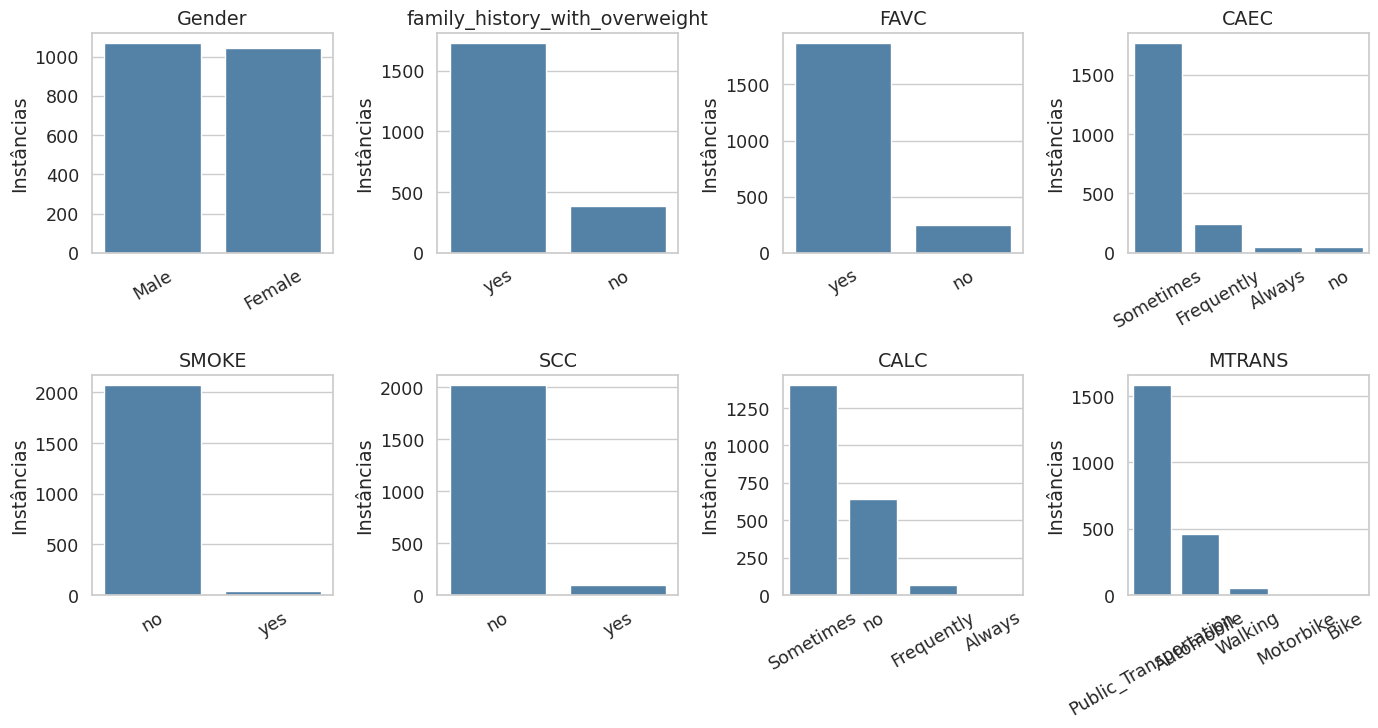

In [8]:
fig, eixos = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, c in zip(eixos.ravel(), [c for c in COLS_CAT if c != TARGET]):
    vc = df[c].value_counts()
    sns.barplot(x=vc.index.astype(str), y=vc.values, ax=ax, color="steelblue")
    ax.set_title(c)
    ax.set_xlabel("")
    ax.set_ylabel("Instâncias")
    ax.tick_params(axis="x", rotation=30)
salvar_figura("01_atributos_categoricos")
plt.show()

### 3.4 Distribuição do atributo classe

,Instâncias,%
NObeyesdad,,
Insufficient_Weight,272,12.9
Normal_Weight,287,13.6
Overweight_Level_I,290,13.7
Overweight_Level_II,290,13.7
Obesity_Type_I,351,16.6
Obesity_Type_II,297,14.1
Obesity_Type_III,324,15.3


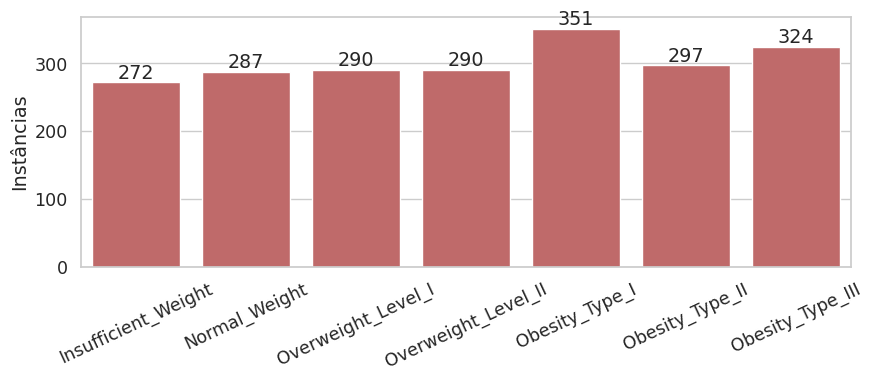

In [9]:
contagem_classe = df[TARGET].value_counts().reindex(ORDEM_CLASSES)
display(pd.DataFrame({"Instâncias": contagem_classe,
                      "%": (100 * contagem_classe / len(df)).round(1)}))

plt.figure(figsize=(9, 4))
ax = sns.barplot(x=contagem_classe.index, y=contagem_classe.values, color="indianred")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=25)
plt.xlabel("")
plt.ylabel("Instâncias")
salvar_figura("02_distribuicao_classe")
plt.show()

### 3.5 Atributos numéricos

,count,mean,std,min,25%,50%,75%,max
Age,2111.0,24.31,6.35,14.00,19.95,22.78,26.00,61.00
Height,2111.0,1.70,0.09,1.45,1.63,1.70,1.77,1.98
Weight,2111.0,86.59,26.19,39.00,65.47,83.00,107.43,173.00
FCVC,2111.0,2.42,0.53,1.00,2.00,2.39,3.00,3.00
NCP,2111.0,2.69,0.78,1.00,2.66,3.00,3.00,4.00
CH2O,2111.0,2.01,0.61,1.00,1.58,2.00,2.48,3.00
FAF,2111.0,1.01,0.85,0.00,0.12,1.00,1.67,3.00
TUE,2111.0,0.66,0.61,0.00,0.00,0.63,1.00,2.00


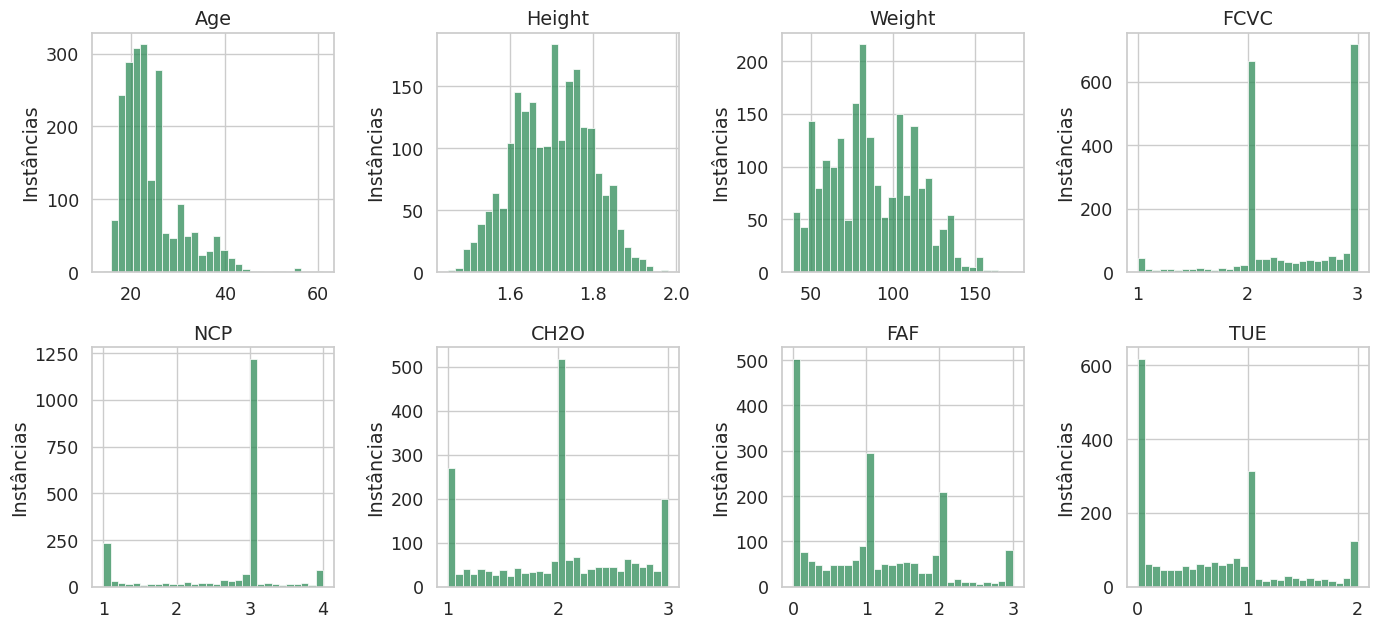

In [10]:
display(df[COLS_NUM].describe().T.round(2))

fig, eixos = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, c in zip(eixos.ravel(), COLS_NUM):
    sns.histplot(df[c], bins=30, ax=ax, color="seagreen")
    ax.set_title(c)
    ax.set_xlabel("")
    ax.set_ylabel("Instâncias")
salvar_figura("03_histogramas_numericos")
plt.show()

### 3.6 Relação entre o IMC e o atributo classe

Como o atributo classe foi definido a partir do IMC, os atributos `Height` e `Weight` são, isoladamente, suficientes para separar as classes com pouca sobreposição. Essa constatação motivou as duas variações de pré-processamento descritas na seção 4.

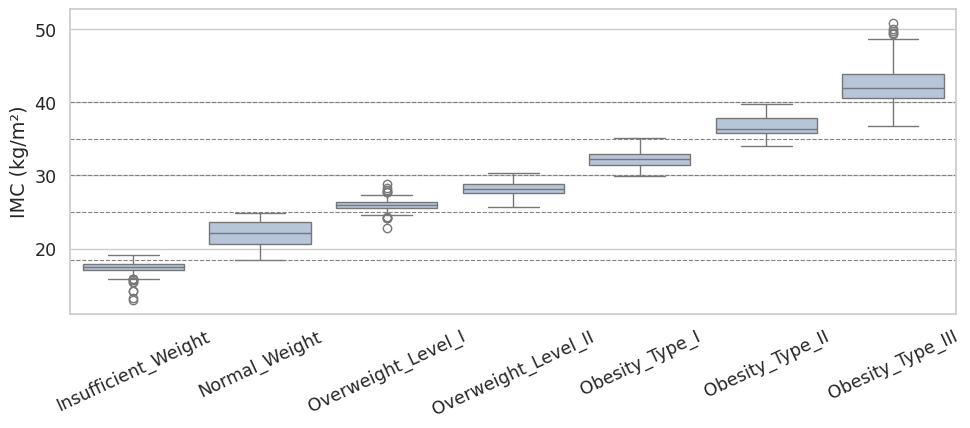

In [11]:
imc = df["Weight"] / df["Height"] ** 2
plt.figure(figsize=(10, 4.5))
sns.boxplot(x=df[TARGET], y=imc, order=ORDEM_CLASSES, color="lightsteelblue")
for limite in (18.5, 25, 30, 35, 40):
    plt.axhline(limite, ls="--", lw=0.8, color="gray")
plt.xticks(rotation=25)
plt.ylabel("IMC (kg/m²)")
plt.xlabel("")
salvar_figura("04_imc_por_classe")
plt.show()

A geração sintética também produziu classes com perfis muito homogêneos. A tabela a seguir mostra a distribuição de gênero, o consumo médio de vegetais (`FCVC`) e a idade média em cada classe.

In [12]:
perfil = pd.crosstab(df[TARGET], df["Gender"]).reindex(ORDEM_CLASSES)
perfil["FCVC médio"] = df.groupby(TARGET)["FCVC"].mean().reindex(ORDEM_CLASSES).round(2)
perfil["Idade média"] = df.groupby(TARGET)["Age"].mean().reindex(ORDEM_CLASSES).round(1)
perfil

Gender,Female,Male,FCVC médio,Idade média
NObeyesdad,,,,
Insufficient_Weight,173,99,2.48,19.8
Normal_Weight,141,146,2.33,21.7
Overweight_Level_I,145,145,2.26,23.4
Overweight_Level_II,103,187,2.26,27.0
Obesity_Type_I,156,195,2.19,25.9
Obesity_Type_II,2,295,2.39,28.2
Obesity_Type_III,323,1,3.00,23.5


## 4. Pré-processamento

As seguintes etapas foram aplicadas às duas variações:

1. Remoção das linhas duplicadas, para evitar que um mesmo registro apareça simultaneamente nos conjuntos de treino e de teste.
2. Arredondamento de `FCVC`, `NCP`, `CH2O`, `FAF` e `TUE` para o inteiro mais próximo, restaurando a escala original do questionário.
3. Codificação dos atributos categóricos. Os binários (`Gender`, `family_history_with_overweight`, `FAVC`, `SMOKE` e `SCC`) foram convertidos para 0 e 1. Os ordinais `CAEC` e `CALC` foram mapeados para 0 (no), 1 (Sometimes), 2 (Frequently) e 3 (Always). O atributo nominal `MTRANS` foi transformado por codificação *one-hot*.
4. Manutenção do atributo classe como nominal.
5. Padronização dos atributos (média 0 e desvio padrão 1) aplicada somente ao KNN, que é sensível à escala. O padronizador integra um `Pipeline` e é ajustado apenas com os dados de treino de cada partição.

Foram avaliadas duas variações:

| Variação | Atributos utilizados | Objetivo |
|---|---|---|
| P1 (completo) | Todos os preditores, inclusive `Height` e `Weight` | Medir o desempenho com todas as informações disponíveis |
| P2 (somente hábitos) | Todos os preditores, exceto `Height` e `Weight` | Verificar se os hábitos e o perfil, sem medidas corporais, permitem estimar o nível de obesidade |

In [13]:
MAPA_BINARIO = {"Gender": {"Female": 0, "Male": 1},
                "family_history_with_overweight": {"no": 0, "yes": 1},
                "FAVC": {"no": 0, "yes": 1},
                "SMOKE": {"no": 0, "yes": 1},
                "SCC": {"no": 0, "yes": 1}}
MAPA_FREQUENCIA = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}


def preprocessar(dados):
    d = dados.drop_duplicates().reset_index(drop=True).copy()
    for c in ORDINAIS_NUM:
        d[c] = d[c].round().astype(int)
    for c, mapa in MAPA_BINARIO.items():
        d[c] = d[c].map(mapa).astype(int)
    for c in ("CAEC", "CALC"):
        d[c] = d[c].map(MAPA_FREQUENCIA).astype(int)
    d = pd.get_dummies(d, columns=["MTRANS"], prefix="MTRANS", dtype=int)
    colunas = [c for c in d.columns if c != TARGET] + [TARGET]
    return d[colunas]


df_proc = preprocessar(df)
logger.info(f"Pré-processamento: {len(df)} para {len(df_proc)} linhas, "
            f"{len(df) - len(df_proc)} duplicatas removidas, {df_proc.shape[1] - 1} preditores")

VARIACOES = {
    "P1_completo": df_proc,
    "P2_so_habitos": df_proc.drop(columns=["Height", "Weight"]),
}
for nome, dados in VARIACOES.items():
    arq = DIR_PROCESSADO / f"obesidade_{nome}.csv"
    dados.to_csv(arq, index=False)
    logger.info(f"{nome}: {dados.shape[0]} linhas e {dados.shape[1] - 1} preditores salvos em {arq.relative_to(BASE)}")

df_proc.head()

2026-11-20 00:10:16 | Pré-processamento: 2111 para 2087 linhas, 24 duplicatas removidas, 20 preditores
2026-11-20 00:10:16 | P1_completo: 2087 linhas e 20 preditores salvos em data/processed/obesidade_P1_completo.csv
2026-11-20 00:10:16 | P2_so_habitos: 2087 linhas e 18 preditores salvos em data/processed/obesidade_P2_so_habitos.csv


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS_Automobile,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking,NObeyesdad
0,0,21.0,1.62,64.0,1,0,2,3,1,0,2,0,0,1,0,0,0,0,1,0,Normal_Weight
1,0,21.0,1.52,56.0,1,0,3,3,1,1,3,1,3,0,1,0,0,0,1,0,Normal_Weight
2,1,23.0,1.80,77.0,1,0,2,3,1,0,2,0,2,1,2,0,0,0,1,0,Normal_Weight
3,1,27.0,1.80,87.0,0,0,3,3,1,0,2,0,2,0,2,0,0,0,0,1,Overweight_Level_I
4,1,22.0,1.78,89.8,0,0,2,1,1,0,2,0,0,0,1,0,0,0,1,0,Overweight_Level_II


## 5. Experimentos

Foram comparados três algoritmos de classificação:

| Algoritmo | Configuração |
|---|---|
| Árvore de Decisão (CART) | `DecisionTreeClassifier(random_state=42)` |
| Random Forest | `RandomForestClassifier(n_estimators=200, random_state=42)` |
| K vizinhos mais próximos (KNN) | `StandardScaler` seguido de `KNeighborsClassifier(n_neighbors=5)` |

A avaliação utilizou validação cruzada estratificada com 10 partições (*folds*), com embaralhamento e semente 42. Em cada partição, o modelo é treinado com 90% dos dados e testado com os 10% restantes. As métricas reportadas são as médias das 10 partições: acurácia, precisão, revocação (*recall*) e medida F (*F-measure*), sendo as três últimas calculadas pela média macro entre as sete classes. O tempo de processamento corresponde ao tempo médio de treinamento por partição, em segundos, medido com `time.perf_counter()` em um único núcleo de processamento. As predições de cada partição são armazenadas para a análise por classe e para a construção das matrizes de confusão.

In [14]:
MODELOS = {
    "Árvore de Decisão": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
    "KNN (k=5)": Pipeline([("padronizacao", StandardScaler()),
                           ("knn", KNeighborsClassifier(n_neighbors=5))]),
}


def avaliar(nome_variacao, dados):
    X, y = dados.drop(columns=[TARGET]), dados[TARGET]
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    por_fold, predicoes = [], {}
    logger.info(f"Variação {nome_variacao}: {X.shape[0]} instâncias e {X.shape[1]} preditores")
    for nome_modelo, modelo in MODELOS.items():
        y_oof = pd.Series(index=y.index, dtype=object)
        for fold, (i_tr, i_te) in enumerate(skf.split(X, y), start=1):
            m = clone(modelo)
            t0 = time.perf_counter()
            m.fit(X.iloc[i_tr], y.iloc[i_tr])
            t_treino = time.perf_counter() - t0
            t0 = time.perf_counter()
            pred = m.predict(X.iloc[i_te])
            t_pred = time.perf_counter() - t0
            y_oof.iloc[i_te] = pred
            y_te = y.iloc[i_te]
            reg = {"Variação": nome_variacao, "Algoritmo": nome_modelo, "Fold": fold,
                   "Acurácia": accuracy_score(y_te, pred),
                   "Precisão": precision_score(y_te, pred, average="macro", zero_division=0),
                   "Recall": recall_score(y_te, pred, average="macro", zero_division=0),
                   "F-Measure": f1_score(y_te, pred, average="macro", zero_division=0),
                   "Tempo de treino (s)": t_treino, "Tempo de predição (s)": t_pred}
            por_fold.append(reg)
            logger.info(f"{nome_variacao} | {nome_modelo:<18} | fold {fold:02d} | "
                        f"acc={reg['Acurácia']:.4f} f1={reg['F-Measure']:.4f} treino={t_treino:.4f}s")
        predicoes[nome_modelo] = y_oof
    por_fold = pd.DataFrame(por_fold)
    resumo = (por_fold.groupby("Algoritmo", sort=False)
              [["Acurácia", "Precisão", "Recall", "F-Measure", "Tempo de treino (s)", "Tempo de predição (s)"]]
              .agg(["mean", "std"]))
    por_fold.to_csv(DIR_LOGS / f"metricas_por_fold_{nome_variacao}.csv", index=False)
    return resumo, por_fold, predicoes, y


RESULTADOS = {nome: avaliar(nome, dados) for nome, dados in VARIACOES.items()}

2026-11-20 00:10:16 | Variação P1_completo: 2087 instâncias e 20 preditores
2026-11-20 00:10:16 | P1_completo | Árvore de Decisão  | fold 01 | acc=0.9569 f1=0.9564 treino=0.0143s
2026-11-20 00:10:16 | P1_completo | Árvore de Decisão  | fold 02 | acc=0.9234 f1=0.9187 treino=0.0141s
2026-11-20 00:10:16 | P1_completo | Árvore de Decisão  | fold 03 | acc=0.9234 f1=0.9204 treino=0.0277s
2026-11-20 00:10:16 | P1_completo | Árvore de Decisão  | fold 04 | acc=0.9282 f1=0.9261 treino=0.0134s
2026-11-20 00:10:16 | P1_completo | Árvore de Decisão  | fold 05 | acc=0.9569 f1=0.9554 treino=0.0210s
2026-11-20 00:10:16 | P1_completo | Árvore de Decisão  | fold 06 | acc=0.9617 f1=0.9604 treino=0.0285s
2026-11-20 00:10:16 | P1_completo | Árvore de Decisão  | fold 07 | acc=0.9378 f1=0.9341 treino=0.0329s
2026-11-20 00:10:16 | P1_completo | Árvore de Decisão  | fold 08 | acc=0.9375 f1=0.9333 treino=0.0127s
2026-11-20 00:10:16 | P1_completo | Árvore de Decisão  | fold 09 | acc=0.9519 f1=0.9505 treino=0.013

## 6. Resultados

Para cada variação de pré-processamento é apresentada uma tabela no formato solicitado no enunciado, com as médias das 10 partições, seguida da versão com os desvios padrão.

In [15]:
def tabela_relatorio(resumo):
    m = resumo.xs("mean", axis=1, level=1)
    t = pd.DataFrame({
        "Acurácia": (100 * m["Acurácia"]).map(lambda v: f"{v:.2f}%"),
        "Precisão": m["Precisão"].map(lambda v: f"{v:.4f}"),
        "Recall": m["Recall"].map(lambda v: f"{v:.4f}"),
        "F-Measure": m["F-Measure"].map(lambda v: f"{v:.4f}"),
        "Tempo de processamento (s)": m["Tempo de treino (s)"].map(lambda v: f"{v:.4f}"),
    })
    t.index.name = "Algoritmo"
    return t


def tabela_detalhada(resumo):
    t = pd.DataFrame(index=resumo.index)
    for met in ["Acurácia", "Precisão", "Recall", "F-Measure", "Tempo de treino (s)", "Tempo de predição (s)"]:
        t[met] = [f"{a:.4f} ± {b:.4f}" for a, b in zip(resumo[(met, "mean")], resumo[(met, "std")])]
    return t


for nome_variacao, (resumo, _, _, _) in RESULTADOS.items():
    tab = tabela_relatorio(resumo)
    tab.to_csv(DIR_LOGS / f"resultados_{nome_variacao}.csv")
    tabela_detalhada(resumo).to_csv(DIR_LOGS / f"resultados_detalhados_{nome_variacao}.csv")
    print(f"\nResultados da variação {nome_variacao}")
    display(tab)
    display(tabela_detalhada(resumo))


Resultados da variação P1_completo


,Acurácia,Precisão,Recall,F-Measure,Tempo de processamento (s)
Algoritmo,,,,,
Árvore de Decisão,94.30%,0.9422,0.9407,0.9407,0.0194
Random Forest,94.92%,0.9492,0.9471,0.9473,0.6489
KNN (k=5),78.44%,0.7777,0.7792,0.7724,0.0055


,Acurácia,Precisão,Recall,F-Measure,Tempo de treino (s),Tempo de predição (s)
Algoritmo,,,,,,
Árvore de Decisão,0.9430 ± 0.0147,0.9422 ± 0.0163,0.9407 ± 0.0157,0.9407 ± 0.0159,0.0194 ± 0.0076,0.0035 ± 0.0026
Random Forest,0.9492 ± 0.0181,0.9492 ± 0.0177,0.9471 ± 0.0191,0.9473 ± 0.0188,0.6489 ± 0.2436,0.0212 ± 0.0085
KNN (k=5),0.7844 ± 0.0147,0.7777 ± 0.0169,0.7792 ± 0.0154,0.7724 ± 0.0159,0.0055 ± 0.0006,0.0064 ± 0.0074



Resultados da variação P2_so_habitos


,Acurácia,Precisão,Recall,F-Measure,Tempo de processamento (s)
Algoritmo,,,,,
Árvore de Decisão,74.18%,0.7374,0.7361,0.7340,0.0097
Random Forest,80.50%,0.8042,0.8005,0.7991,0.4879
KNN (k=5),72.59%,0.7217,0.7201,0.7129,0.0053


,Acurácia,Precisão,Recall,F-Measure,Tempo de treino (s),Tempo de predição (s)
Algoritmo,,,,,,
Árvore de Decisão,0.7418 ± 0.0348,0.7374 ± 0.0383,0.7361 ± 0.0368,0.7340 ± 0.0374,0.0097 ± 0.0015,0.0016 ± 0.0007
Random Forest,0.8050 ± 0.0237,0.8042 ± 0.0254,0.8005 ± 0.0261,0.7991 ± 0.0256,0.4879 ± 0.0764,0.0205 ± 0.0039
KNN (k=5),0.7259 ± 0.0178,0.7217 ± 0.0259,0.7201 ± 0.0180,0.7129 ± 0.0206,0.0053 ± 0.0004,0.0042 ± 0.0002


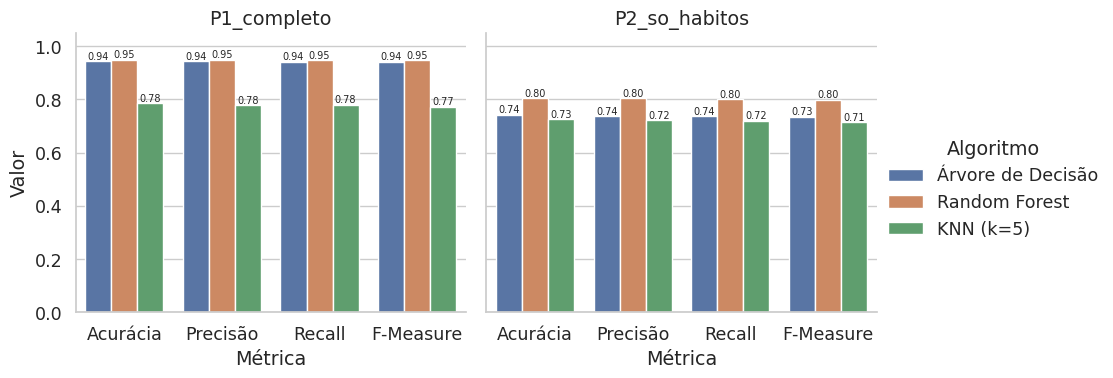

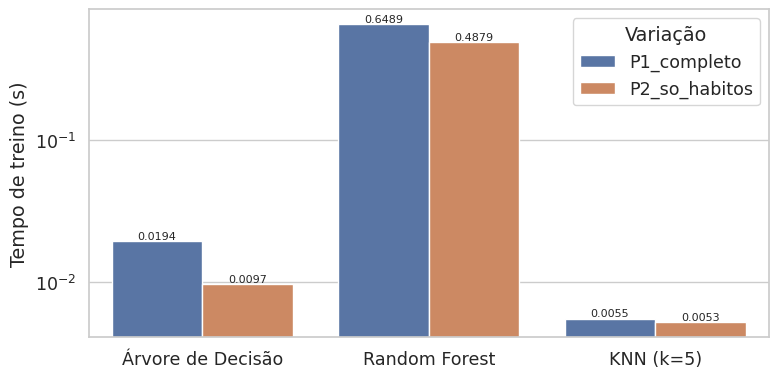

In [16]:
comparativo = pd.concat(
    {nome: res.xs("mean", axis=1, level=1)[["Acurácia", "Precisão", "Recall", "F-Measure"]]
     for nome, (res, _, _, _) in RESULTADOS.items()},
    names=["Variação", "Algoritmo"]).reset_index()
longo = comparativo.melt(id_vars=["Variação", "Algoritmo"], var_name="Métrica", value_name="Valor")

g = sns.catplot(data=longo, x="Métrica", y="Valor", hue="Algoritmo", col="Variação",
                kind="bar", height=4, aspect=1.15)
g.set_titles("{col_name}")
for ax in g.axes.ravel():
    ax.set_ylim(0, 1.05)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.2f", fontsize=7)
plt.savefig(DIR_FIGURAS / "06_comparativo_metricas.png", dpi=150, bbox_inches="tight")
plt.show()

tempos = pd.concat(
    {nome: res[("Tempo de treino (s)", "mean")] for nome, (res, _, _, _) in RESULTADOS.items()},
    names=["Variação", "Algoritmo"]).rename("Tempo de treino (s)").reset_index()
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=tempos, x="Algoritmo", y="Tempo de treino (s)", hue="Variação")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.4f", fontsize=8)
plt.yscale("log")
plt.xlabel("")
salvar_figura("07_tempo_treino")
plt.show()

## 7. Melhor e pior resultado

Os algoritmos foram ordenados pela medida F com média macro, que considera precisão e revocação de forma equilibrada e atribui o mesmo peso a todas as classes. O desempenho por classe foi calculado a partir das predições obtidas na validação cruzada.


Variação P1_completo
Melhor algoritmo: Random Forest. Acurácia 94.92%, precisão 0.9492, recall 0.9471, F-Measure 0.9473, treino 0.6489 s por partição.
Melhor classe: Obesity_Type_III (F-Measure 0.9969). Pior classe: Normal_Weight (F-Measure 0.8669).
2026-11-20 00:10:30 | P1_completo | melhor algoritmo: Random Forest | melhor classe: Obesity_Type_III | pior classe: Normal_Weight


,Precisão,Recall,F-Measure,Instâncias
Insufficient_Weight,0.9806,0.9476,0.9638,267
Normal_Weight,0.8355,0.9007,0.8669,282
Overweight_Level_I,0.9077,0.8913,0.8995,276
Overweight_Level_II,0.9379,0.9379,0.9379,290
Obesity_Type_I,0.9855,0.9687,0.9770,351
Obesity_Type_II,0.9932,0.9865,0.9899,297
Obesity_Type_III,0.9969,0.9969,0.9969,324


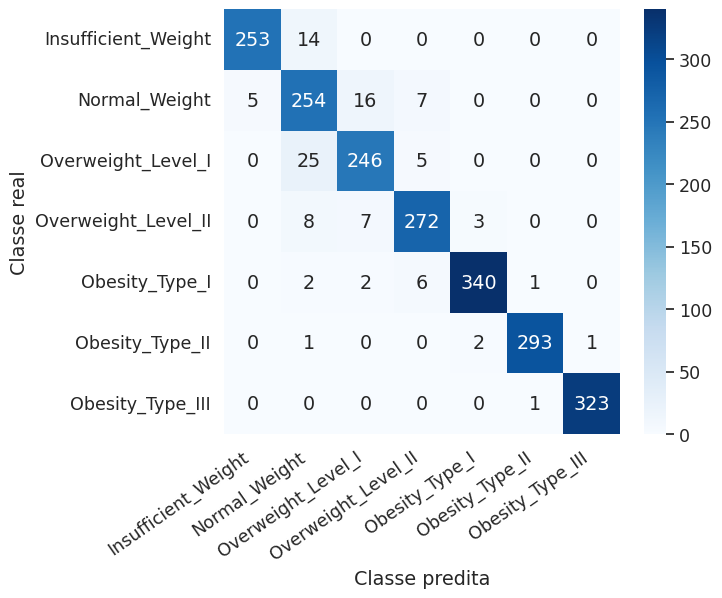

Pior algoritmo: KNN (k=5). Acurácia 78.44%, precisão 0.7777, recall 0.7792, F-Measure 0.7724, treino 0.0055 s por partição.
Melhor classe: Obesity_Type_III (F-Measure 0.9862). Pior classe: Normal_Weight (F-Measure 0.5620).
2026-11-20 00:10:31 | P1_completo | pior algoritmo: KNN (k=5) | melhor classe: Obesity_Type_III | pior classe: Normal_Weight


,Precisão,Recall,F-Measure,Instâncias
Insufficient_Weight,0.7438,0.9026,0.8156,267
Normal_Weight,0.6197,0.5142,0.5620,282
Overweight_Level_I,0.7467,0.6087,0.6707,276
Overweight_Level_II,0.7537,0.6966,0.7240,290
Obesity_Type_I,0.7610,0.7892,0.7748,351
Obesity_Type_II,0.8222,0.9495,0.8812,297
Obesity_Type_III,0.9787,0.9938,0.9862,324


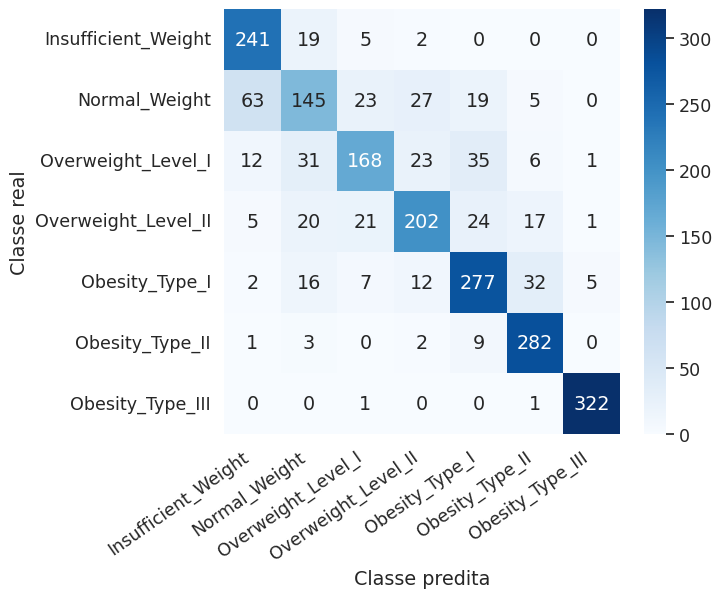


Variação P2_so_habitos
Melhor algoritmo: Random Forest. Acurácia 80.50%, precisão 0.8042, recall 0.8005, F-Measure 0.7991, treino 0.4879 s por partição.
Melhor classe: Obesity_Type_III (F-Measure 0.9877). Pior classe: Normal_Weight (F-Measure 0.6165).
2026-11-20 00:10:31 | P2_so_habitos | melhor algoritmo: Random Forest | melhor classe: Obesity_Type_III | pior classe: Normal_Weight


,Precisão,Recall,F-Measure,Instâncias
Insufficient_Weight,0.8262,0.8727,0.8488,267
Normal_Weight,0.6232,0.6099,0.6165,282
Overweight_Level_I,0.7869,0.6957,0.7385,276
Overweight_Level_II,0.7536,0.7172,0.7350,290
Obesity_Type_I,0.7895,0.8120,0.8006,351
Obesity_Type_II,0.8375,0.9024,0.8687,297
Obesity_Type_III,0.9817,0.9938,0.9877,324


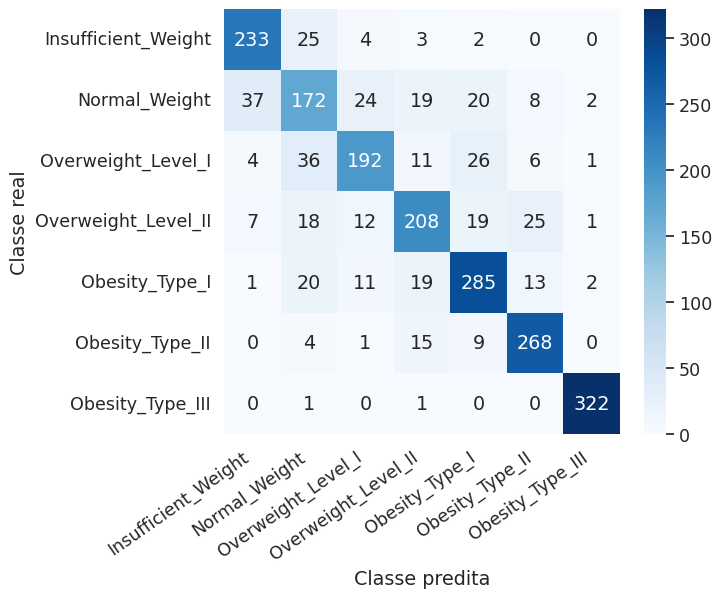

Pior algoritmo: KNN (k=5). Acurácia 72.59%, precisão 0.7217, recall 0.7201, F-Measure 0.7129, treino 0.0053 s por partição.
Melhor classe: Obesity_Type_III (F-Measure 0.9742). Pior classe: Normal_Weight (F-Measure 0.5166).
2026-11-20 00:10:32 | P2_so_habitos | pior algoritmo: KNN (k=5) | melhor classe: Obesity_Type_III | pior classe: Normal_Weight


,Precisão,Recall,F-Measure,Instâncias
Insufficient_Weight,0.6697,0.8277,0.7404,267
Normal_Weight,0.5764,0.4681,0.5166,282
Overweight_Level_I,0.6783,0.5652,0.6166,276
Overweight_Level_II,0.7269,0.5690,0.6383,290
Obesity_Type_I,0.6755,0.7236,0.6988,351
Obesity_Type_II,0.7389,0.8956,0.8097,297
Obesity_Type_III,0.9582,0.9907,0.9742,324


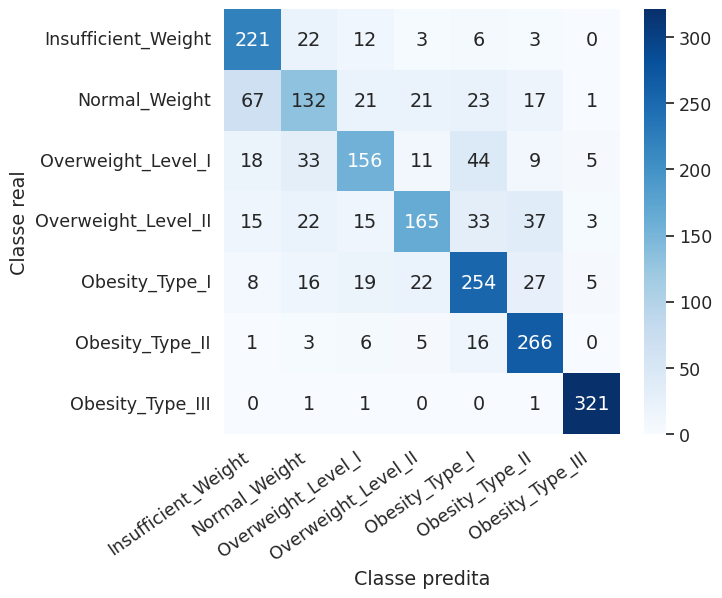

In [17]:
def relatorio_por_classe(y, y_pred):
    rep = classification_report(y, y_pred, labels=ORDEM_CLASSES, output_dict=True, zero_division=0)
    t = pd.DataFrame(rep).T.loc[ORDEM_CLASSES, ["precision", "recall", "f1-score", "support"]]
    t.columns = ["Precisão", "Recall", "F-Measure", "Instâncias"]
    t["Instâncias"] = t["Instâncias"].astype(int)
    return t


def destacar(t):
    return (t.style.format({"Precisão": "{:.4f}", "Recall": "{:.4f}", "F-Measure": "{:.4f}"})
            .highlight_max(subset=["F-Measure"], color="#b6e3b6")
            .highlight_min(subset=["F-Measure"], color="#f4b6b6"))


def plot_matriz(y, y_pred, arquivo):
    cm = confusion_matrix(y, y_pred, labels=ORDEM_CLASSES)
    plt.figure(figsize=(7.5, 6.2))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=ORDEM_CLASSES, yticklabels=ORDEM_CLASSES)
    plt.xlabel("Classe predita")
    plt.ylabel("Classe real")
    plt.xticks(rotation=35, ha="right")
    salvar_figura(arquivo)
    plt.show()


for nome_variacao, (resumo, _, predicoes, y) in RESULTADOS.items():
    medias = resumo.xs("mean", axis=1, level=1).sort_values("F-Measure", ascending=False)
    print(f"\nVariação {nome_variacao}")
    for rotulo, alg in (("Melhor", medias.index[0]), ("Pior", medias.index[-1])):
        m = medias.loc[alg]
        rep = relatorio_por_classe(y, predicoes[alg])
        rep.to_csv(DIR_LOGS / f"por_classe_{nome_variacao}_{alg.split()[0]}.csv")
        top, bot = rep["F-Measure"].idxmax(), rep["F-Measure"].idxmin()
        print(f"{rotulo} algoritmo: {alg}. Acurácia {100 * m['Acurácia']:.2f}%, precisão {m['Precisão']:.4f}, "
              f"recall {m['Recall']:.4f}, F-Measure {m['F-Measure']:.4f}, "
              f"treino {m['Tempo de treino (s)']:.4f} s por partição.")
        print(f"Melhor classe: {top} (F-Measure {rep.loc[top, 'F-Measure']:.4f}). "
              f"Pior classe: {bot} (F-Measure {rep.loc[bot, 'F-Measure']:.4f}).")
        logger.info(f"{nome_variacao} | {rotulo.lower()} algoritmo: {alg} | melhor classe: {top} | pior classe: {bot}")
        display(destacar(rep))
        plot_matriz(y, predicoes[alg], f"08_matriz_{nome_variacao}_{alg.split()[0]}")

### 7.1 Importância dos atributos

Importância dos atributos, medida pela redução média de impureza, no Random Forest treinado com todos os dados de cada variação.

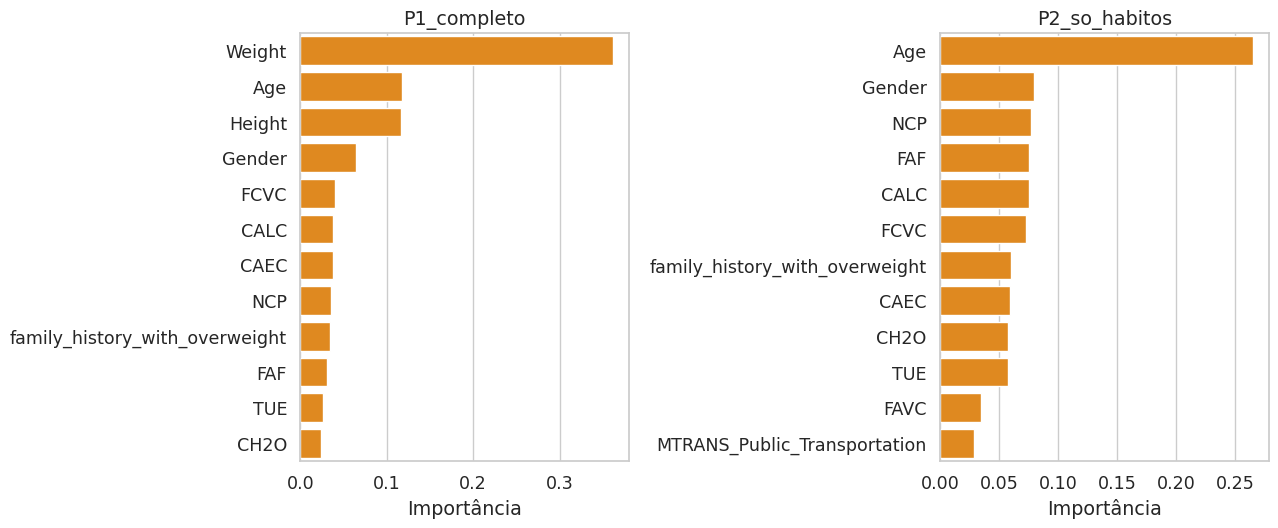

In [18]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (nome_variacao, dados) in zip(eixos, VARIACOES.items()):
    X, y = dados.drop(columns=[TARGET]), dados[TARGET]
    rf = clone(MODELOS["Random Forest"]).fit(X, y)
    imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(12)
    sns.barplot(x=imp.values, y=imp.index, ax=ax, color="darkorange")
    ax.set_title(nome_variacao)
    ax.set_xlabel("Importância")
    ax.set_ylabel("")
salvar_figura("09_importancia_atributos")
plt.show()

## 8. Treinamento final e gravação dos modelos

Cada algoritmo é treinado com todos os dados de cada variação e gravado na pasta `models/` no formato `joblib`.

In [19]:
ARQUIVO_MODELO = {"Árvore de Decisão": "arvore_decisao", "Random Forest": "random_forest", "KNN (k=5)": "knn"}

registros = []
for nome_variacao, dados in VARIACOES.items():
    X, y = dados.drop(columns=[TARGET]), dados[TARGET]
    for nome_modelo, modelo in MODELOS.items():
        m = clone(modelo)
        t0 = time.perf_counter()
        m.fit(X, y)
        t_treino = time.perf_counter() - t0
        arq = DIR_MODELOS / f"{nome_variacao}_{ARQUIVO_MODELO[nome_modelo]}.joblib"
        joblib.dump(m, arq, compress=3)
        registros.append({"Variação": nome_variacao, "Algoritmo": nome_modelo,
                          "Tempo de treino (s)": round(t_treino, 4), "Arquivo": str(arq.relative_to(BASE))})
        logger.info(f"Modelo final {nome_variacao} | {nome_modelo} | {t_treino:.4f}s | {arq.name}")
modelos_finais = pd.DataFrame(registros)
modelos_finais.to_csv(DIR_LOGS / "modelos_finais.csv", index=False)
modelos_finais

2026-11-20 00:10:34 | Modelo final P1_completo | Árvore de Decisão | 0.0127s | P1_completo_arvore_decisao.joblib
2026-11-20 00:10:35 | Modelo final P1_completo | Random Forest | 0.5200s | P1_completo_random_forest.joblib
2026-11-20 00:10:35 | Modelo final P1_completo | KNN (k=5) | 0.0057s | P1_completo_knn.joblib
2026-11-20 00:10:35 | Modelo final P2_so_habitos | Árvore de Decisão | 0.0082s | P2_so_habitos_arvore_decisao.joblib
2026-11-20 00:10:35 | Modelo final P2_so_habitos | Random Forest | 0.4753s | P2_so_habitos_random_forest.joblib
2026-11-20 00:10:35 | Modelo final P2_so_habitos | KNN (k=5) | 0.0059s | P2_so_habitos_knn.joblib


,Variação,Algoritmo,Tempo de treino (s),Arquivo
0,P1_completo,Árvore de Decisão,0.0127,models/P1_completo_arvore_decisao.joblib
1,P1_completo,Random Forest,0.5200,models/P1_completo_random_forest.joblib
2,P1_completo,KNN (k=5),0.0057,models/P1_completo_knn.joblib
3,P2_so_habitos,Árvore de Decisão,0.0082,models/P2_so_habitos_arvore_decisao.joblib
4,P2_so_habitos,Random Forest,0.4753,models/P2_so_habitos_random_forest.joblib
5,P2_so_habitos,KNN (k=5),0.0059,models/P2_so_habitos_knn.joblib


In [20]:
print("Python      ", platform.python_version())
print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib  ", plt.matplotlib.__version__)
print("seaborn     ", sns.__version__)

Python       3.13.18
pandas       2.2.3
numpy        2.4.6
scikit-learn 1.6.1
matplotlib   3.10.0
seaborn      0.13.2


## 9. Conclusões

O conjunto de dados possui 2111 instâncias e 17 atributos, sendo 16 preditores e o atributo classe `NObeyesdad`. Não há valores ausentes, mas foram identificadas 24 linhas duplicadas e valores fracionários em atributos ordinais, ambos tratados no pré-processamento. O atributo mais desbalanceado é `SMOKE`, no qual 97,9% dos registros correspondem ao valor "no". O atributo classe, por sua vez, é praticamente balanceado em razão da aplicação do SMOTE pelos autores.

O Random Forest obteve o melhor desempenho nas duas variações. Na variação P1, alcançou acurácia de 94,92%, precisão de 0,9492, revocação de 0,9471 e medida F de 0,9473. Na variação P2, obteve acurácia de 80,50%, precisão de 0,8042, revocação de 0,8005 e medida F de 0,7991. Em P1, a Árvore de Decisão apresentou resultado muito próximo (acurácia de 94,30%) com tempo de treinamento cerca de 33 vezes menor, o que a torna a opção de melhor custo e benefício nesse cenário. Em P2, a vantagem do Random Forest sobre a Árvore de Decisão foi de aproximadamente 6 pontos percentuais de acurácia.

O KNN apresentou o pior desempenho nas duas variações, com acurácia de 78,44% em P1 e de 72,59% em P2. Embora seja o algoritmo de treinamento mais rápido, o KNN atribui o mesmo peso a todos os atributos no cálculo da distância. Assim, os atributos `Height` e `Weight`, que são determinantes para a classe, têm sua influência diluída entre os demais. As árvores de decisão, ao contrário, selecionam os atributos mais informativos durante a construção do modelo.

Em todos os casos, a classe com melhor resultado foi `Obesity_Type_III`, com medida F entre 0,9742 e 0,9969, e a classe com pior resultado foi `Normal_Weight`, com medida F entre 0,5166 e 0,8669. A classe `Obesity_Type_III` apresenta um perfil bastante homogêneo, composto quase exclusivamente por mulheres com `FCVC` igual a 3, o que facilita seu reconhecimento mesmo sem as medidas corporais. A classe `Normal_Weight` ocupa uma posição intermediária e é confundida principalmente com as classes vizinhas `Insufficient_Weight` e `Overweight_Level_I`. De forma geral, os erros concentram-se entre classes adjacentes.

O artigo que descreve o conjunto de dados (PALECHOR; DE LA HOZ MANOTAS, 2019) não apresenta resultados de classificação e remete ao estudo de De-La-Hoz-Correa et al. (2019). Nesse estudo, os autores compararam árvore de decisão (J48), Naive Bayes e regressão logística (Simple Logistic) na ferramenta Weka e obtiveram o melhor resultado com o J48, com precisão de 97,4%. Na variação P1 deste trabalho, que utiliza os mesmos atributos, a Árvore de Decisão atingiu precisão de 0,9422 e o Random Forest de 0,9492, valores entre 2,5 e 3,2 pontos percentuais inferiores. A diferença pode ser atribuída a fatores metodológicos: neste trabalho foram removidas as linhas duplicadas, os atributos ordinais foram arredondados e a precisão foi calculada pela média macro, enquanto o Weka reporta, por padrão, a média ponderada. Além disso, as implementações e os parâmetros de poda do J48 diferem dos da árvore CART utilizada pelo scikit-learn.

Por fim, o resultado de P1 deve ser interpretado com cautela, pois o atributo classe foi definido a partir do IMC, calculado com `Height` e `Weight`, de modo que o modelo essencialmente reaprende essa relação. O resultado de P2 é mais relevante do ponto de vista prático, pois indica que os hábitos e o perfil do indivíduo permitem estimar o nível de obesidade com acurácia próxima de 80%. Ainda assim, como 77% dos registros são sintéticos, é provável que o desempenho seja inferior em dados exclusivamente reais. Como trabalhos futuros, sugere-se o ajuste de hiperparâmetros por busca em grade, a seleção de atributos para o KNN e a avaliação dos modelos apenas com os registros reais.